# CB, HD, and RF comparison: m22 261019

Free-moving session **3** (Basler), RF session **1**, Probe A.
Read saved CB-positive and HD-class-3 classifications. Each pair uses its own shared neurons; the primary CB-HD comparison does not require an RF. Missing classifications are unassessed, not negative. No thresholds are relaxed.

Run from `~/Developer/rfmapping` on `hhw9l84` with the `rfmapping` kernel. This notebook reads existing saved inputs only. Canonical CB outputs were explicitly generated with `cb_cd_analysis.ipynb`, using 100 shuffles and seed 20261019 where first-time generation was needed.

The count table records saved HD thresholds and CB coverage. Statistics use 30-bin peaks and pairing permutations (seed 1; 10,000 requested, exact enumeration when the permutation space is smaller). P values are unadjusted. Native-resolution peaks and full source provenance are also exported.


In [1]:
%matplotlib inline
from pathlib import Path
import json

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

from EBB.center_cell_io import file_evidence, load_center_tc
from EBB.center_profiles import cb_profiles
from HD.profiles import hd_pick, hd_profiles, load_hd_tc
from RF.profiles import load_rf_profiles, rf_pick
from Utils.direction_comparison import (
    normalize_tc, paired_peak_angles, peak_sum_statistics, plot_comparison_heatmaps,
    plot_peak_direction_sums, prepare_comparison, profile_coordinates,
    recording_profiles, resample_profiles, tcRange,
)
from Utils.plotting import apply_light_plot_style, plot_direction_comparison
from Utils.statistic_utils import compare_direction_angles

apply_light_plot_style()


In [2]:
recording_root = Path("/mnt/senzailab/Kai/#Recording")
mouse, date, probe = 'm22', '261019', "A"
fm_sessions = (3,)
rf_session = 1
phase = "baseline"
comparison_bins = 30
hd_class = 3
cb_cells_only = True  # False shows descriptive curves from all units, including unassessed units.
rf_max_zero_bins = 2  # Count measured zeros on the native RF projection before resampling.

# Each pair selects its own shared units; RF does not restrict the primary CB-HD pair.
pairs = [("HD3", "CB3"), ("HD3", "RF1"), ("RF1", "CB3")]
sort_by = "HD"  # "HD", "CB", "RF", or "first"; use first when the requested type is absent.
comparison_modes = ("native", "aligned", "sum")
is_wrap = True
statistics_permutations = 10_000
statistics_seed = 1
density_bin_count = 16

save_outputs = True
show_figures = True
show_modes = ("native", "sum")  # Aligned figures are still exported.
figure_size = (10, 5)
output_dir = Path("output/cb_hd_rf_comparison") / f"{mouse}_{date}"
# Change output_dir to keep a separate export when changing selections/settings.
hd_angle_conventions = {3: 'Basler native CW'}

plot_options = dict(
    figsize=figure_size, vmin=0, vmax=1, colorbar_label="Normalized response",
)
if sort_by not in ("HD", "CB", "RF", "first"):
    raise ValueError("sort_by must be HD, CB, RF, or first")


## Load native curves, select units, then prepare the 30-bin display

HD uses the saved `hd_class`; CB uses the saved nullable `cb_is_cell`. HD and CB display curves pool **raw counts and occupancy before division**, with no new smoothing or classification. RF reads the saved native RF-only x projection and applies the existing maximum-zero-bin selection before interpolation. Entirely unavailable RF curves are excluded explicitly; partial missing bins are retained.

Saved HD3 uses Basler native CW angles. CB remains clockwise egocentric (0° forward, +90° right), and RF retains its native x-angle sign. Wrapping angles changes their numeric representation only. Peak sums/alignment are **native-angle arithmetic**, not a conversion into one common physical reference frame.

Statistics below use peaks from the displayed 30-bin curves, as in `hd_rf_comparison.ipynb`. The native-resolution peak columns are exported alongside them so rebinning/interpolation effects remain visible. Native bin ties select the first saved bin; display ties select the first prepared bin.


In [3]:
loaded_native = {}
selected_native = {}
profiles = {}
profile_kinds = {}
source_evidence = []
source_metadata = {}
classification_tables = {}
count_rows = []


def recording_table(table, label):
    return recording_profiles(table, mouse=mouse, date=date, label=label)


for session in fm_sessions:
    session_dir = recording_root / mouse / date / f"{date}_{session}"
    hd_key, cb_key = f"HD{session}", f"CB{session}"

    hd_source = session_dir / "data/tuning_curves" / f"Probe{probe}" / "tuning_curves.tc"
    hd_data = load_hd_tc(hd_source)
    hd_native = hd_profiles(hd_data, probe=probe, bins=len(hd_data["occupancy_time_s"]))
    loaded_native[hd_key] = recording_table(hd_native, f"HD session {session}")
    selected_native[hd_key] = hd_pick(loaded_native[hd_key], hd_class=hd_class)
    hd_display = hd_profiles(hd_data, probe=probe, bins=comparison_bins, hd_class=hd_class)
    profiles[hd_key] = recording_table(
        resample_profiles(hd_display, range=tcRange(False), bins=comparison_bins),
        f"HD session {session} | class {hd_class}",
    )
    profile_kinds[hd_key] = "HD"
    source_evidence.append({"profile": hd_key, **file_evidence(hd_source)})
    source_metadata[hd_key] = {
        "saved_metadata": hd_data.get("metadata", {}),
        "angle_convention": hd_angle_conventions[session],
    }
    hd_classes = pd.Series(hd_data["unit_data"]["hd_class"])
    count_rows.append({
        "profile": hd_key, "loaded_units": len(hd_native),
        "measured_units": int(np.isfinite(hd_native.to_numpy()).any(axis=1).sum()),
        "selected_units": len(profiles[hd_key]),
        "assessed_units": int(hd_classes.notna().sum()),
        "unassessed_units": int(hd_classes.isna().sum()),
        "positive_units": int(hd_classes.eq(hd_class).sum()),
        "selection": f"saved HD class {hd_class}",
        "hd_kappa_cutoff": hd_data["metadata"]["classification"]["kappa_cutoff"],
        "native_bins": hd_native.shape[1], "display_bins": comparison_bins,
        "spatial_coverage": np.nan,
        "angle_convention": hd_angle_conventions[session],
    })

    center_dir = session_dir / "data/center_cells" / f"Probe{probe}" / phase
    cb_source = center_dir / "cb_tuning.tc"
    cb_data = load_center_tc(cb_source)
    cb_native = cb_profiles(cb_data, probe=probe)
    loaded_native[cb_key] = recording_table(cb_native, f"CB session {session}")
    selected_native[cb_key] = recording_table(
        cb_profiles(cb_data, probe=probe, cells_only=cb_cells_only),
        f"CB session {session}",
    )
    cb_label = (f"CB session {session} | saved CB cells" if cb_cells_only else
                f"CB session {session} | all units, descriptive only")
    cb_display = cb_profiles(
        cb_data, probe=probe, bins=comparison_bins, cells_only=cb_cells_only,
    )
    profiles[cb_key] = recording_table(
        resample_profiles(cb_display, range=tcRange(True), bins=comparison_bins), cb_label,
    )
    profile_kinds[cb_key] = "CB"
    source_evidence.append({"profile": cb_key, **file_evidence(cb_source)})
    manifest_path = center_dir / "manifest.json"
    source_evidence.append({"profile": cb_key, **file_evidence(manifest_path)})
    source_metadata[cb_key] = json.loads(manifest_path.read_text(encoding="utf-8"))
    classification = pd.DataFrame(cb_data["unit_data"], index=cb_data["unit_id"])
    classification.index.name = "unit_id"
    classification_tables[cb_key] = classification
    cb_labels = pd.array(classification["cb_is_cell"], dtype="boolean")
    coverage = classification["spatial_coverage"].iloc[0] if len(classification) else np.nan
    count_rows.append({
        "profile": cb_key, "loaded_units": len(cb_native),
        "measured_units": int(np.isfinite(cb_native.to_numpy()).any(axis=1).sum()),
        "selected_units": len(profiles[cb_key]),
        "assessed_units": int((~cb_labels.isna()).sum()),
        "unassessed_units": int(cb_labels.isna().sum()),
        "positive_units": int(cb_labels.sum()),
        "selection": "saved CB-positive" if cb_cells_only else "all units, descriptive only",
        "native_bins": cb_native.shape[1], "display_bins": comparison_bins,
        "spatial_coverage": coverage,
        "angle_convention": "CW egocentric; 0 front, +90 right",
    })

rf_key = f"RF{rf_session}"
rf_source = (
    recording_root / mouse / date / f"{date}_{rf_session}" / "data" /
    f"regular_unitsSpikeCounts_{date}_{rf_session}_Probe{probe}_1d_rfonly.csv"
)
rf_native = recording_table(
    load_rf_profiles(rf_source, probe=probe, range=tcRange(True)), f"RF session {rf_session}",
)
loaded_native[rf_key] = rf_native
rf_measured = np.isfinite(rf_native.to_numpy()).any(axis=1)
selected_native[rf_key] = rf_pick(rf_native.loc[rf_measured], max_zero_bins=rf_max_zero_bins)
profiles[rf_key] = resample_profiles(
    selected_native[rf_key], range=tcRange(True), bins=comparison_bins, fill_value=0,
)
profile_kinds[rf_key] = "RF"
source_evidence.append({"profile": rf_key, **file_evidence(rf_source)})
source_metadata[rf_key] = {
    "projection": "saved native RF-only x projection; no detection rerun",
    "angle_convention": "native RF x angles",
}
count_rows.append({
    "profile": rf_key, "loaded_units": len(rf_native),
    "measured_units": int(rf_measured.sum()),
    "selected_units": len(profiles[rf_key]),
    "assessed_units": np.nan, "unassessed_units": np.nan, "positive_units": np.nan,
    "selection": f"measured RF-only curves; <= {rf_max_zero_bins} native zero bins",
    "native_bins": rf_native.shape[1], "display_bins": comparison_bins,
    "spatial_coverage": np.nan, "angle_convention": "native RF x angles",
})

counts = pd.DataFrame(count_rows).set_index("profile")
display(counts)
for key, classification in classification_tables.items():
    display(classification["cb_status"].value_counts(dropna=False).rename(f"{key} saved status"))


,loaded_units,measured_units,selected_units,assessed_units,unassessed_units,positive_units,selection,hd_kappa_cutoff,native_bins,display_bins,spatial_coverage,angle_convention
profile,,,,,,,,,,,,
HD3,217,217,25,217.0,0.0,25.0,saved HD class 3,0.25,180,30,NaN,Basler native CW
CB3,221,221,1,151.0,70.0,1.0,saved CB-positive,NaN,120,30,1.0,"CW egocentric; 0 front, +90 right"
RF1,136,10,10,NaN,NaN,NaN,measured RF-only curves; <= 2 native zero bins,NaN,30,30,NaN,native RF x angles


cb_status
classified                                                                      151
insufficient_spikes;undefined_split_half_stability                               42
insufficient_spikes                                                              18
insufficient_spikes;undefined_tuning_strength;undefined_split_half_stability     10
Name: CB3 saved status, dtype: int64

## Calculate paired comparisons and statistics

`sort_by` chooses the reference type within each configured pair; otherwise the first named profile is the reference. All views use the same row normalization and native-view ordering. The pair table also reports how many shared units have a selected RF1, without restricting the primary CB–HD pair.

Circular correlation and Spearman Mantel tests require at least three finite direction pairs (10,000 permutations, seed 1). Peak-sum concentration uses the same `peak_sum_statistics` helper as the existing RF–HD notebook. The tests describe selected neurons and their saved angle conventions; p values are unadjusted for multiple comparisons.


In [4]:
results = {}
summary_rows = []

for first, second in pairs:
    pair_id = f"{first}_{second}"
    if sort_by != "first" and profile_kinds[second] == sort_by:
        reference_key, matched_key = second, first
    else:
        reference_key, matched_key = first, second
    units = profiles[reference_key].index.intersection(profiles[matched_key].index)
    summary = {
        "pair": pair_id, "reference": reference_key, "matched": matched_key,
        "reference_selected_units": len(profiles[reference_key]),
        "matched_selected_units": len(profiles[matched_key]),
        "shared_selected_units": len(units),
        "shared_with_selected_RF": len(units.intersection(profiles[rf_key].index)),
        "finite_direction_pairs": 0, "display_bins": comparison_bins,
        "cb_selection": "saved CB-positive" if cb_cells_only else "all units, descriptive only",
        "status": "no_shared_selected_units",
        "circular_rho": np.nan, "circular_permutation_p": np.nan,
        "mantel_rho": np.nan, "mantel_permutation_p": np.nan,
        "peak_sum_r": np.nan, "peak_sum_rayleigh_p": np.nan,
    }
    result = {
        "reference_key": reference_key, "matched_key": matched_key,
        "units": units, "comparisons": {}, "direction": None,
    }
    results[pair_id] = result
    summary_rows.append(summary)
    if not len(units):
        continue

    reference = normalize_tc(profiles[reference_key].loc[units])
    matched = normalize_tc(profiles[matched_key].loc[units])
    native = prepare_comparison(reference, matched, is_wrap=is_wrap)
    result.update(reference=reference, matched=matched)
    for mode in comparison_modes:
        result["comparisons"][mode] = (
            native if mode == "native" else prepare_comparison(
                reference, matched, mode=mode, order=native["order"],
                bins=comparison_bins, is_wrap=is_wrap,
                reference_fill_value=0 if profile_kinds[reference_key] == "RF" else np.nan,
                matched_fill_value=0 if profile_kinds[matched_key] == "RF" else np.nan,
            )
        )

    source_peaks = paired_peak_angles(
        selected_native[reference_key].loc[units], selected_native[matched_key].loc[units],
        order=native["order"], is_wrap=is_wrap,
    ).add_prefix("source_native_")
    result["peaks"] = native["peaks"].join(source_peaks)
    finite_peaks = native["peaks"].dropna(subset=["reference_peak_deg", "matched_peak_deg"])
    result["finite_peaks"] = finite_peaks
    result["peak_sums"] = peak_sum_statistics(native["peaks"])
    summary["finite_direction_pairs"] = len(finite_peaks)
    summary["peak_sum_r"] = result["peak_sums"]["statistics"]["r"]
    summary["peak_sum_rayleigh_p"] = result["peak_sums"]["statistics"]["p"]
    summary["status"] = "fewer_than_three_finite_pairs"
    if len(finite_peaks) >= 3:
        direction = compare_direction_angles(
            finite_peaks.reference_peak_deg.to_numpy(),
            finite_peaks.matched_peak_deg.to_numpy(),
            n_permutations=statistics_permutations, random_seed=statistics_seed,
        )
        result["direction"] = direction
        summary.update(
            status="computed",
            circular_rho=direction["same_unit"]["circular_correlation_rho"],
            circular_permutation_p=direction["same_unit"]["permutation_p"],
            mantel_rho=direction["pairwise"]["spearman_mantel_rho"],
            mantel_permutation_p=direction["pairwise"]["permutation_p"],
        )

pair_summary = pd.DataFrame(summary_rows).set_index("pair")
display(pair_summary)


,reference,matched,reference_selected_units,matched_selected_units,shared_selected_units,shared_with_selected_RF,finite_direction_pairs,display_bins,cb_selection,status,circular_rho,circular_permutation_p,mantel_rho,mantel_permutation_p,peak_sum_r,peak_sum_rayleigh_p
pair,,,,,,,,,,,,,,,,
HD3_CB3,HD3,CB3,25,1,0,0,0,30,saved CB-positive,no_shared_selected_units,NaN,NaN,NaN,NaN,NaN,NaN
HD3_RF1,HD3,RF1,25,10,6,6,6,30,saved CB-positive,computed,-0.894422,0.038889,0.411341,0.094444,0.714624,0.039574
RF1_CB3,RF1,CB3,10,1,0,0,0,30,saved CB-positive,no_shared_selected_units,NaN,NaN,NaN,NaN,NaN,NaN


## Save tables and source provenance

Exports are written only here and in the plotting cell. They include selected rates/counts before normalization, the peak values underlying every comparison, CB classification evidence, source hashes, saved CB manifests, and the settings used. Re-running replaces exports under the configured output directory; use a different directory to retain a separate analysis.


In [5]:
if save_outputs:
    output_dir.mkdir(parents=True, exist_ok=True)
    counts.to_csv(output_dir / "profile_counts.csv")
    pair_summary.to_csv(output_dir / "pair_statistics.csv")
    pd.DataFrame(source_evidence).to_csv(output_dir / "source_files.csv", index=False)
    for key, table in profiles.items():
        table.to_csv(output_dir / f"{key}_selected_display_curves.csv")
        selected_native[key].to_csv(output_dir / f"{key}_selected_native_curves.csv")
    for key, table in classification_tables.items():
        table.to_csv(output_dir / f"{key}_saved_classifications.csv")
    for pair_id, result in results.items():
        pair_dir = output_dir / pair_id
        pair_dir.mkdir(parents=True, exist_ok=True)
        result["units"].to_frame(index=False).to_csv(pair_dir / "paired_units.csv", index=False)
        if "peaks" in result:
            result["peaks"].to_csv(pair_dir / "paired_peaks.csv")
            peak_sums = result["peak_sums"]
            pd.DataFrame({
                "left_deg": peak_sums["edges"][:-1],
                "right_deg": peak_sums["edges"][1:],
                "unit_count": peak_sums["counts"],
            }).to_csv(pair_dir / "peak_sum_histogram.csv", index=False)
    provenance = {
        "mouse": mouse, "date": date, "probe": probe, "phase": phase,
        "fm_sessions": fm_sessions, "rf_session": rf_session,
        "hd_class": hd_class, "cb_cells_only": cb_cells_only,
        "rf_max_zero_bins": rf_max_zero_bins, "comparison_bins": comparison_bins,
        "pairs": pairs, "sort_by": sort_by, "comparison_modes": comparison_modes,
        "is_wrap": is_wrap, "statistics_permutations": statistics_permutations,
        "statistics_seed": statistics_seed,
        "peak_statistics_grid": "prepared display curves; source-native peaks exported separately",
        "coordinate_policy": "preserve native signs; sums are native-angle arithmetic",
        "sources": source_evidence, "source_metadata": source_metadata,
    }
    (output_dir / "provenance.json").write_text(
        json.dumps(provenance, indent=2) + "\n", encoding="utf-8",
    )
    print(f"Saved tables and provenance: {output_dir.resolve()}")


Saved tables and provenance: /home/kai/Developer/rfmapping/output/cb_hd_rf_comparison/m22_261019


## Plot native, aligned, and sum views

Heatmaps share a 0–1 response scale. CB/HD values are rates before normalization; RF values are spike counts. All figures and exported PNG/SVG files have opaque white backgrounds. Empty selected pairs are reported and skipped; no classification threshold is relaxed.


HD3_CB3: no shared selected units; see profile_counts and saved CB statuses.
HD3_RF1: 6 shared units; sorted by HD3


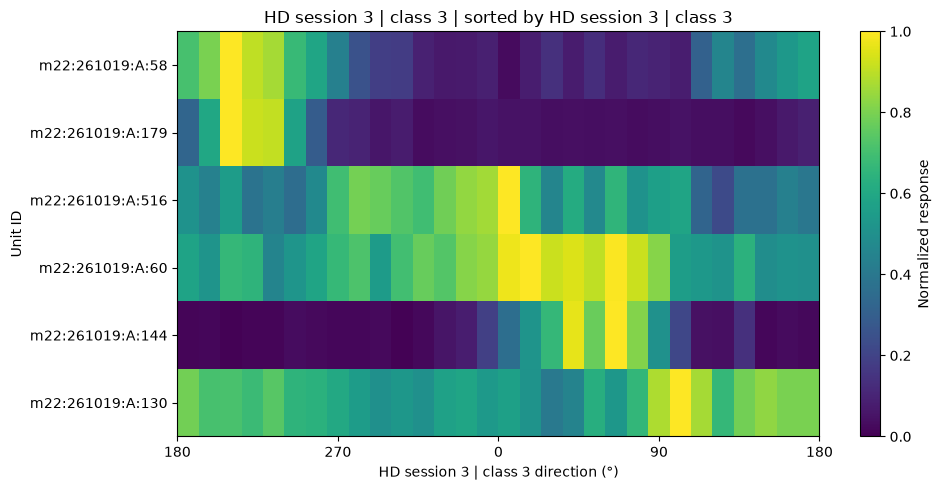

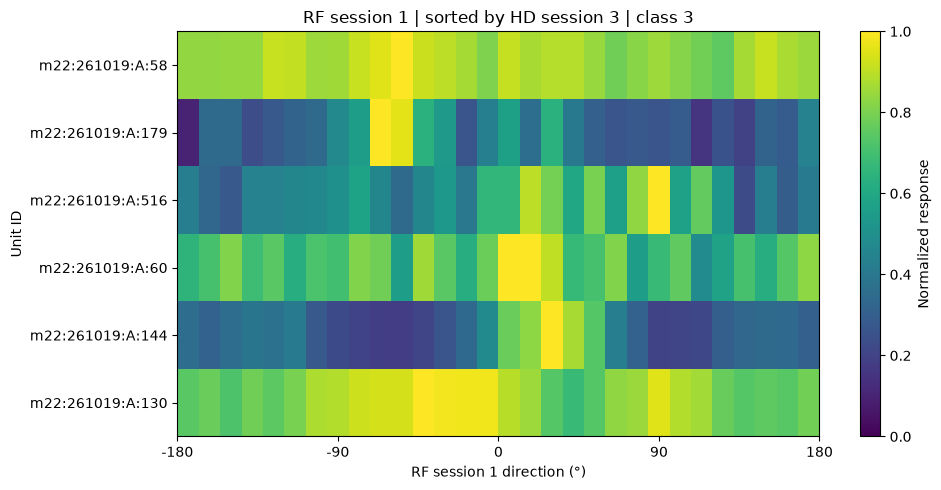

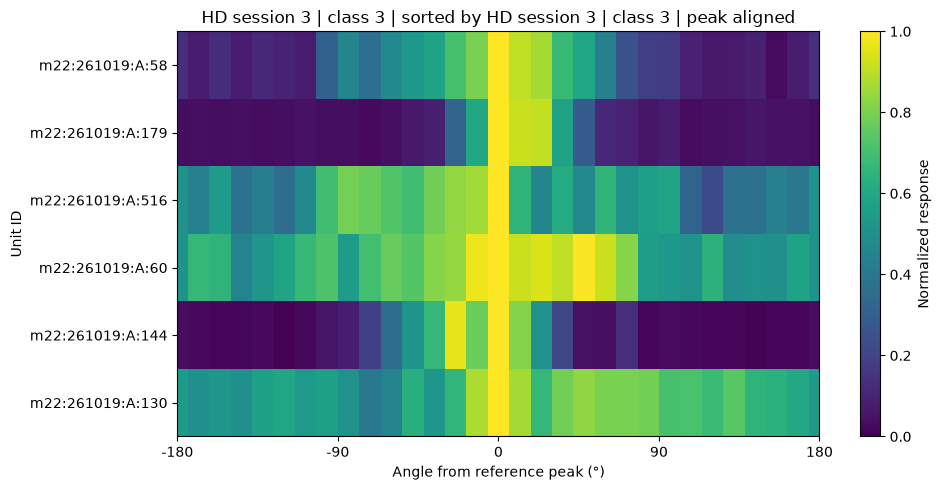

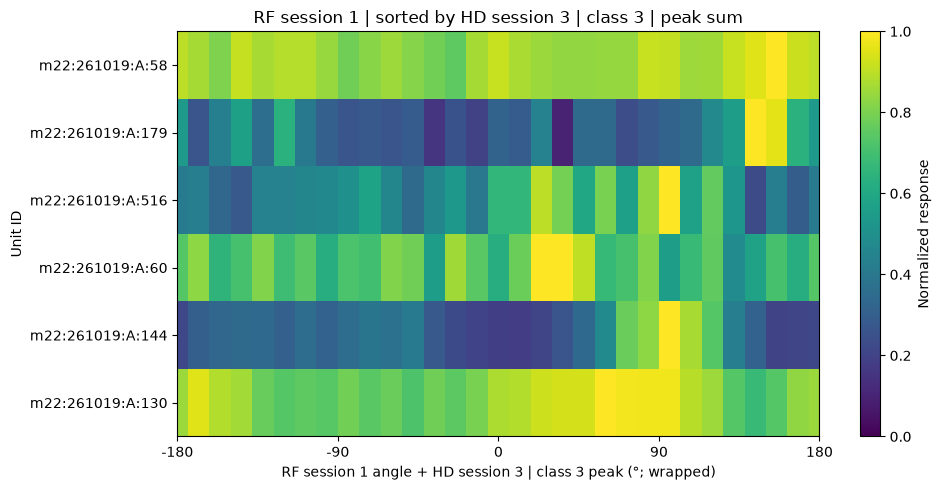

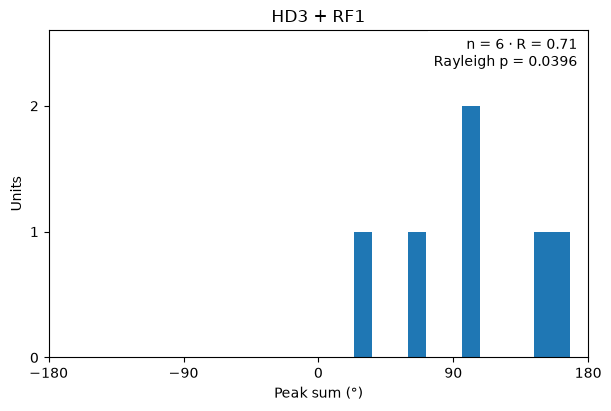

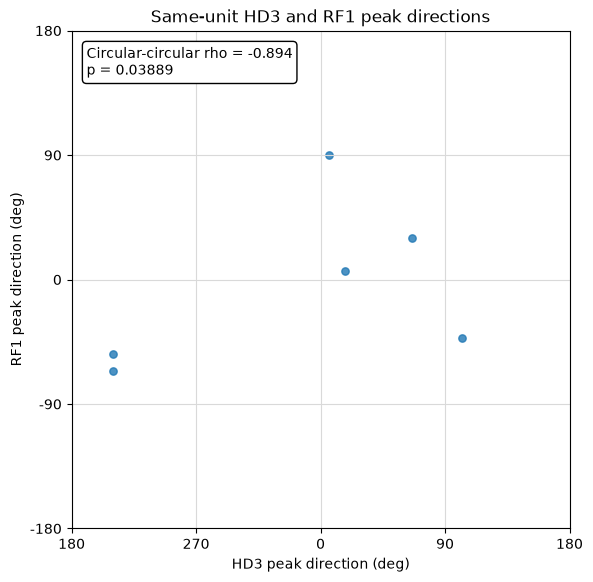

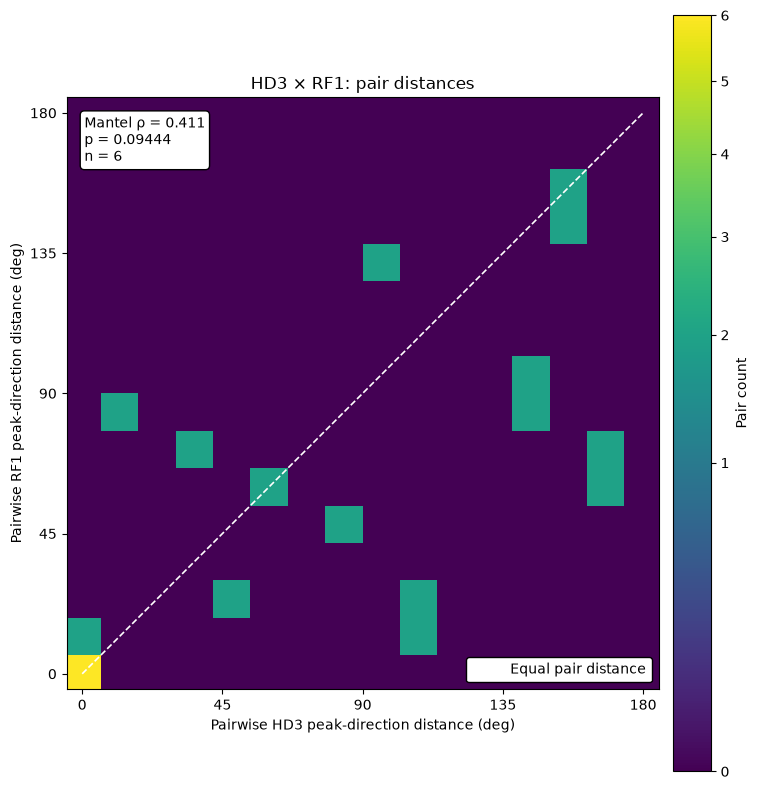

RF1_CB3: no shared selected units; see profile_counts and saved CB statuses.


,reference,matched,reference_selected_units,matched_selected_units,shared_selected_units,shared_with_selected_RF,finite_direction_pairs,display_bins,cb_selection,status,circular_rho,circular_permutation_p,mantel_rho,mantel_permutation_p,peak_sum_r,peak_sum_rayleigh_p
pair,,,,,,,,,,,,,,,,
HD3_CB3,HD3,CB3,25,1,0,0,0,30,saved CB-positive,no_shared_selected_units,NaN,NaN,NaN,NaN,NaN,NaN
HD3_RF1,HD3,RF1,25,10,6,6,6,30,saved CB-positive,computed,-0.894422,0.038889,0.411341,0.094444,0.714624,0.039574
RF1_CB3,RF1,CB3,10,1,0,0,0,30,saved CB-positive,no_shared_selected_units,NaN,NaN,NaN,NaN,NaN,NaN


Comparison exports: /home/kai/Developer/rfmapping/output/cb_hd_rf_comparison/m22_261019


In [6]:
def present_figure(figure, pair_id, name, *, show=True):
    if save_outputs:
        pair_dir = output_dir / pair_id
        pair_dir.mkdir(parents=True, exist_ok=True)
        for suffix in ("png", "svg"):
            figure.savefig(pair_dir / f"{name}.{suffix}", dpi=180,
                           facecolor="white", transparent=False)
    if show_figures and show:
        display(figure)
    plt.close(figure)


short_labels = {
    key: f"{key} (all units)" if kind == "CB" and not cb_cells_only else key
    for key, kind in profile_kinds.items()
}

for pair_id, result in results.items():
    if not len(result["units"]):
        print(f"{pair_id}: no shared selected units; see profile_counts and saved CB statuses.")
        continue
    reference_key, matched_key = result["reference_key"], result["matched_key"]
    print(f"{pair_id}: {len(result['units'])} shared units; sorted by {reference_key}")
    for mode, comparison in result["comparisons"].items():
        figures = plot_comparison_heatmaps(comparison, show=False, **plot_options)
        for key, (figure, _) in zip((reference_key, matched_key), figures):
            present_figure(figure, pair_id, f"{mode}_{key}_sorted_by_{reference_key}",
                           show=mode in show_modes)

    figure = plot_peak_direction_sums(
        result["peak_sums"], hd_label=short_labels[reference_key],
        rf_label=short_labels[matched_key],
    )
    present_figure(figure, pair_id, "peak_sums")
    if result["direction"] is None:
        print(f"{pair_id}: fewer than three finite pairs; direction tests skipped.")
        continue
    finite = result["finite_peaks"]
    direction_figures = plot_direction_comparison(
        finite.reference_peak_deg.to_numpy(), finite.matched_peak_deg.to_numpy(),
        result["direction"],
        reference_label=short_labels[reference_key],
        matched_label=short_labels[matched_key],
        reference_ticklabels=profile_coordinates(result["reference"])["ticklabels"],
        matched_ticklabels=profile_coordinates(result["matched"])["ticklabels"],
        density_bin_count=density_bin_count, show=False,
    )
    for number, (figure, _) in enumerate(direction_figures, 1):
        present_figure(figure, pair_id, f"direction_statistics_{number}")

display(pair_summary)
if save_outputs:
    print(f"Comparison exports: {output_dir.resolve()}")
